> **Generated on 18-11-2026 with Claude Code (Opus 5.5, medium effort).**

# Machine-learning approach: k-means runner profiles

This notebook supports the report section *Machine-Learning Approach*. It is a simplified version of `analysis/athlete_profiles/athlete_profiles.ipynb` (same pipeline, same numbers) and contains only what the section uses:

1. Features per workout and per athlete
2. Scaling
3. Choosing *k* → **Figure 2** (`output/chart.png`)
4. k-means with *k* = 3
5. Naming the clusters with a fixed rule
6. The profiles in real units + a **check of every number in the text**

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())
SRC = ROOT / "data" / "endomondo-hr-prediction-v2" / "dataset.parquet"
OUT = ROOT / "analysis" / "report_ml" / "output"
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
MIN_WORKOUTS = 10
K = 3

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
BLUE, ORANGE, AQUA, RED, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, NEUTRAL, RED])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "legend.frameon": False, "lines.linewidth": 2,
})

## 1 · Features

**Per workout** we compute, besides the summary columns, three measures from the time series:

* `efficiency`: speed per heartbeat (km/h per 100 bpm)
* `opening_pace_ratio`: speed in the first 15% of the run / rest (> 1 = starts faster than it can sustain)
* `cardiac_drift_pct`: how much efficiency drops from the 1st to the 2nd half, in %

**Per athlete** we combine their workouts into one row (medians, so one broken run doesn't skew it), using only athletes with **≥ 10 workouts**.

In [2]:
cols = ["user_id", "workout_type", "duration_min", "timestamp", "heart_rate", "speed",
        "hr_mean", "hr_max", "speed_mean", "altitude_gain"]
df = pd.read_parquet(SRC, columns=cols)

hr = np.stack(df["heart_rate"].to_numpy()).astype("float32")
sp = np.stack(df["speed"].to_numpy()).astype("float32")
n_pts = sp.shape[1]
cut15, half = int(n_pts * 0.15), n_pts // 2
ef = sp / np.clip(hr, 1, None)
ef1, ef2 = ef[:, :half].mean(1), ef[:, half:].mean(1)

w = pd.DataFrame({
    "user_id": df["user_id"].to_numpy(),
    "workout_type": df["workout_type"].to_numpy(),
    "date": pd.to_datetime(df["timestamp"].map(lambda t: t[0]).to_numpy(), unit="s"),
    "distance_km": (df["speed_mean"] * df["duration_min"] / 60).to_numpy(),
    "hr_mean": df["hr_mean"].to_numpy(),
    "hr_max": df["hr_max"].to_numpy(),
    "altitude_gain": df["altitude_gain"].to_numpy(),
    "efficiency": 100 * df["speed_mean"].to_numpy() / df["hr_mean"].to_numpy(),
    "speed_cv": sp.std(1) / np.clip(sp.mean(1), 0.1, None),
    "opening_pace_ratio": sp[:, :cut15].mean(1) / np.clip(sp[:, cut15:].mean(1), 0.1, None),
    "cardiac_drift_pct": 100 * (ef1 - ef2) / np.clip(ef1, 1e-6, None),
})

g = w.groupby("user_id")
span_weeks = (g["date"].max() - g["date"].min()).dt.days / 7
athletes = pd.DataFrame({
    "workouts": g.size(),
    "runs_per_week": g.size() / span_weeks.clip(lower=1),
    "distance_km": g["distance_km"].median(),
    "efficiency": g["efficiency"].median(),
    "rel_intensity": g["hr_mean"].median() / g["hr_max"].quantile(0.95),
    "share_intensive": g["workout_type"].apply(lambda s: (s == "INTENSIVE").mean()),
    "speed_cv": g["speed_cv"].median(),
    "opening_pace_ratio": g["opening_pace_ratio"].median(),
    "cardiac_drift_pct": g["cardiac_drift_pct"].median(),
    "climb_m_per_km": g["altitude_gain"].sum() / g["distance_km"].sum(),
})
core = athletes[athletes.workouts >= MIN_WORKOUTS].copy()
print(f"{len(w):,} workouts, {len(athletes)} athletes → {len(core)} athletes with ≥ {MIN_WORKOUTS} workouts")
core.describe().T.round(2)

40,186 workouts, 761 athletes → 569 athletes with ≥ 10 workouts


,count,mean,std,min,25%,50%,75%,max
workouts,569.0,69.35,70.14,10.00,21.00,45.00,89.00,673.00
runs_per_week,569.0,0.68,0.57,0.06,0.28,0.54,0.90,6.42
distance_km,569.0,10.98,2.84,3.12,9.47,10.74,12.47,23.03
efficiency,569.0,7.27,1.05,4.09,6.55,7.24,7.98,10.91
rel_intensity,569.0,0.83,0.04,0.69,0.80,0.83,0.85,0.92
share_intensive,569.0,0.06,0.11,0.00,0.00,0.01,0.07,0.71
speed_cv,569.0,0.11,0.04,0.04,0.08,0.10,0.12,0.32
opening_pace_ratio,569.0,0.98,0.05,0.60,0.96,0.98,1.01,1.17
cardiac_drift_pct,569.0,4.95,3.13,-7.01,3.10,5.08,6.87,16.60
climb_m_per_km,569.0,9.16,4.86,0.73,5.91,8.11,11.39,35.01


| Feature | Meaning |
|---|---|
| `runs_per_week` | training frequency |
| `distance_km` | typical distance per run |
| `efficiency` | speed per heartbeat |
| `rel_intensity` | median HR as a share of the athlete's own peak HR |
| `share_intensive` | share of workouts labelled INTENSIVE in the dataset |
| `speed_cv` | pace variation within a run |
| `opening_pace_ratio` | fast start (> 1) or controlled start (< 1) |
| `cardiac_drift_pct` | efficiency loss during the run |
| `climb_m_per_km` | how hilly the routes are |

## 2 · Scaling

k-means works on distances, so all features must be on the same scale:

1. **log** of the skewed features (frequency, distance, climb)
2. **clip** to the 1st–99th percentile (outliers from broken GPS data)
3. **standardise** to z-scores: 0 = the average athlete, ±1 = one standard deviation

In [3]:
FEATURES = ["runs_per_week", "distance_km", "efficiency", "rel_intensity", "share_intensive",
            "speed_cv", "opening_pace_ratio", "cardiac_drift_pct", "climb_m_per_km"]
LOG_FEATURES = ["runs_per_week", "distance_km", "climb_m_per_km"]

Xr = core[FEATURES].copy()
for c in LOG_FEATURES:
    Xr[c] = np.log1p(Xr[c])
Xr = Xr.clip(Xr.quantile(0.01), Xr.quantile(0.99), axis=1)
X = StandardScaler().fit_transform(Xr)
print("shape:", X.shape, "| mean ≈", X.mean().round(3), "| std ≈", X.std().round(3))

shape: (569, 9) | mean ≈ 0.0 | std ≈ 1.0


## 3 · Choosing *k* (Figure 2)

For *k* = 2…10 we compute:

* **Inertia:** total squared distance of athletes to their cluster centre. It always decreases, so look for the "elbow".
* **Silhouette:** how much closer an athlete is to their own cluster than to the nearest other one (higher = better).
* **Davies-Bouldin:** spread within clusters relative to the distance between them (lower = better).
* **Bootstrap stability:** refit on 20 resampled datasets and measure with the adjusted Rand index whether the same clusters come back (1 = identical).

,inertia,silhouette,davies_bouldin,stability
k,,,,
2,4316.997,0.157,2.177,0.802
3,3937.926,0.158,1.941,0.554
4,3622.188,0.137,1.930,0.432
5,3364.138,0.124,1.897,0.525
6,3164.338,0.120,1.879,0.479
7,3001.633,0.113,1.860,0.505
8,2886.740,0.110,1.862,0.428
9,2790.025,0.107,1.852,0.427
10,2702.686,0.107,1.830,0.423


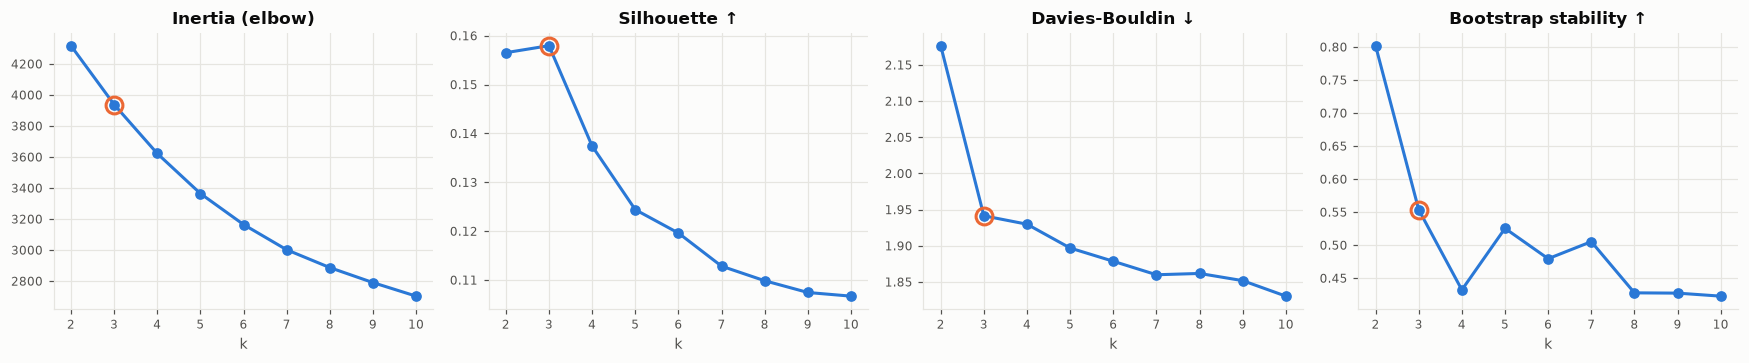

In [4]:
rng = np.random.default_rng(SEED)
rows = []
for k in range(2, 11):
    km_k = KMeans(k, n_init=20, random_state=SEED).fit(X)
    aris = []
    for _ in range(20):
        idx = rng.choice(len(X), len(X), replace=True)
        kb = KMeans(k, n_init=5, random_state=int(rng.integers(1e9))).fit(X[idx])
        aris.append(adjusted_rand_score(km_k.labels_, kb.predict(X)))
    rows.append(dict(k=k, inertia=km_k.inertia_, silhouette=silhouette_score(X, km_k.labels_),
                     davies_bouldin=davies_bouldin_score(X, km_k.labels_), stability=np.mean(aris)))
scores = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
titles = {"inertia": "Inertia (elbow)", "silhouette": "Silhouette ↑",
          "davies_bouldin": "Davies-Bouldin ↓", "stability": "Bootstrap stability ↑"}
for ax, (col, title) in zip(axes, titles.items()):
    ax.plot(scores.index, scores[col], color=BLUE, marker="o", ms=6)
    ax.plot(K, scores.loc[K, col], "o", ms=11, mfc="none", mec=ORANGE, mew=2)
    ax.set(title=title, xlabel="k", xticks=scores.index)
fig.tight_layout()
fig.savefig(OUT / "chart.png", dpi=200, bbox_inches="tight")
scores.round(3)

**Reading:** *k* = 3 has the highest silhouette (only just above *k* = 2), the Davies-Bouldin index drops clearly compared with *k* = 2, and the stability is moderate. *k* = 2 is more stable but too coarse for profiles; above *k* = 3 the stability drops. The silhouette is low everywhere: athletes form a sliding scale, not sharply separated groups.

## 4 · k-means with *k* = 3

In [5]:
km = KMeans(K, n_init=50, random_state=SEED).fit(X)
centres = pd.DataFrame(km.cluster_centers_, columns=FEATURES)      # in z-scores: 0 = average athlete
print("athletes per cluster:", np.bincount(km.labels_))
centres.round(2)

athletes per cluster: [306 216  47]


,runs_per_week,distance_km,efficiency,rel_intensity,share_intensive,speed_cv,opening_pace_ratio,cardiac_drift_pct,climb_m_per_km
0,0.34,0.44,0.52,-0.24,-0.26,-0.31,-0.45,-0.39,-0.12
1,-0.42,-0.55,-0.65,0.17,-0.24,0.46,0.66,0.51,0.12
2,-0.30,-0.33,-0.44,0.81,2.76,-0.04,-0.04,0.21,0.22


## 5 · Naming the clusters

k-means only returns numbers (0, 1, 2), and that numbering is arbitrary on every refit. So we name the clusters from their **centres**, with a fixed rule:

1. highest `share_intensive` → **Interval-focused**
2. of the remaining two, highest `efficiency` → **Efficient & consistent**
3. the last one → **Fast starter / developing**

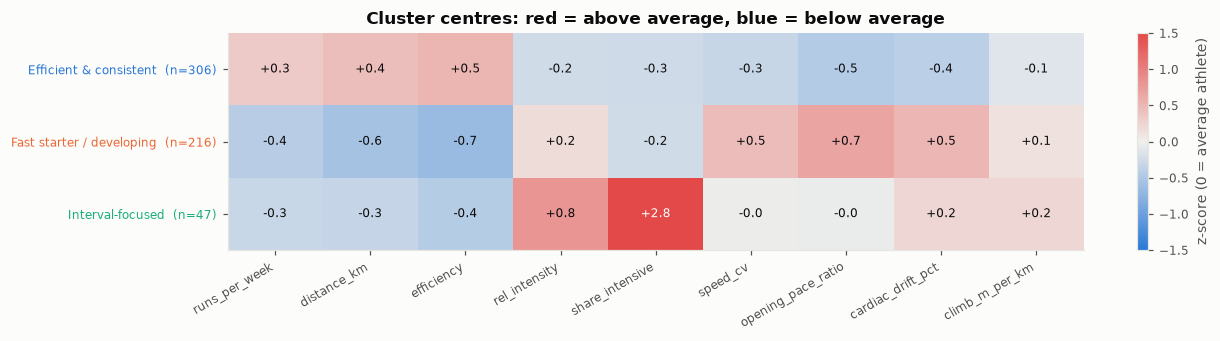

In [6]:
c_int = centres["share_intensive"].idxmax()
c_eff = centres.drop(c_int)["efficiency"].idxmax()
c_dev = (set(centres.index) - {c_int, c_eff}).pop()
NAMES = {c_eff: "Efficient & consistent", c_dev: "Fast starter / developing", c_int: "Interval-focused"}
ORDER = ["Efficient & consistent", "Fast starter / developing", "Interval-focused"]
COLOR = dict(zip(ORDER, [BLUE, ORANGE, AQUA]))
core["profile"] = pd.Categorical([NAMES[l] for l in km.labels_], categories=ORDER)

zp = centres.rename(index=NAMES).loc[ORDER]
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(zp.values, cmap=DIVERGING, vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=30, ha="right")
ax.set_yticks(range(K), [f"{n}  (n={(core.profile == n).sum()})" for n in ORDER])
for tick, n in zip(ax.get_yticklabels(), ORDER):
    tick.set_color(COLOR[n])
for r in range(K):
    for c in range(len(FEATURES)):
        v = zp.iat[r, c]
        ax.text(c, r, f"{v:+.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 1 else INK)
ax.grid(False)
fig.colorbar(im, ax=ax, label="z-score (0 = average athlete)")
ax.set_title("Cluster centres: red = above average, blue = below average")
fig.tight_layout()
fig.savefig(OUT / "cluster_centres.png", dpi=200, bbox_inches="tight")

## 6 · The profiles in real units

Medians per profile. The last table checks every number used in the report text.

In [7]:
profile = core.groupby("profile", observed=False)[FEATURES].median()
profile.insert(0, "athletes", core.profile.value_counts().reindex(ORDER))
profile.round(2).T

profile,Efficient & consistent,Fast starter / developing,Interval-focused
athletes,306.00,216.00,47.00
runs_per_week,0.72,0.36,0.44
distance_km,11.98,9.83,10.05
efficiency,7.78,6.57,6.83
rel_intensity,0.82,0.83,0.86
share_intensive,0.01,0.00,0.33
speed_cv,0.09,0.12,0.10
opening_pace_ratio,0.97,1.01,0.99
cardiac_drift_pct,4.02,6.80,4.98
climb_m_per_km,7.43,8.89,9.37


In [8]:
s = scores.loc[K]
p = profile
checks = [
    ("Silhouette at k = 3",                           "0.158", f"{s.silhouette:.3f}"),
    ("Davies-Bouldin at k = 3",                       "1.94",  f"{s.davies_bouldin:.2f}"),
    ("Bootstrap stability at k = 3",                  "0.55",  f"{s.stability:.2f}"),
    ("Interval-focused: share intensive workouts",    "≈ 1/3", f"{p.loc['Interval-focused', 'share_intensive']:.2f}"),
    ("Interval-focused: rel. HR vs others",           "higher", f"{p.loc['Interval-focused', 'rel_intensity']:.2f} vs "
                                                                f"{p.drop('Interval-focused').rel_intensity.max():.2f}"),
    ("Efficient: cardiac drift",                      "4.0%",  f"{p.loc['Efficient & consistent', 'cardiac_drift_pct']:.1f}%"),
    ("Efficient: runs per week",                      "0.72",  f"{p.loc['Efficient & consistent', 'runs_per_week']:.2f}"),
    ("Efficient: km per run",                         "12.0",  f"{p.loc['Efficient & consistent', 'distance_km']:.1f}"),
    ("Fast starter: opening pace ratio",              "> 1",   f"{p.loc['Fast starter / developing', 'opening_pace_ratio']:.2f}"),
    ("Fast starter: cardiac drift",                   "6.8%",  f"{p.loc['Fast starter / developing', 'cardiac_drift_pct']:.1f}%"),
    ("Fast starter: pace variability vs Efficient",   "higher", f"{p.loc['Fast starter / developing', 'speed_cv']:.3f} vs "
                                                                f"{p.loc['Efficient & consistent', 'speed_cv']:.3f}"),
    ("Fast starter: runs per week",                   "0.36",  f"{p.loc['Fast starter / developing', 'runs_per_week']:.2f}"),
    ("Fast starter: km per run",                      "9.8",   f"{p.loc['Fast starter / developing', 'distance_km']:.1f}"),
]
pd.DataFrame(checks, columns=["claim in report", "report", "notebook"]).set_index("claim in report")

,report,notebook
claim in report,,
Silhouette at k = 3,0.158,0.158
Davies-Bouldin at k = 3,1.94,1.94
Bootstrap stability at k = 3,0.55,0.55
Interval-focused: share intensive workouts,≈ 1/3,0.33
Interval-focused: rel. HR vs others,higher,0.86 vs 0.83
Efficient: cardiac drift,4.0%,4.0%
Efficient: runs per week,0.72,0.72
Efficient: km per run,12.0,12.0
Fast starter: opening pace ratio,> 1,1.01


### The profiles on a map

Each dot is an athlete, projected onto 2 dimensions with PCA. The colours overlap at the edges: the profiles are tendencies, not hard boxes.

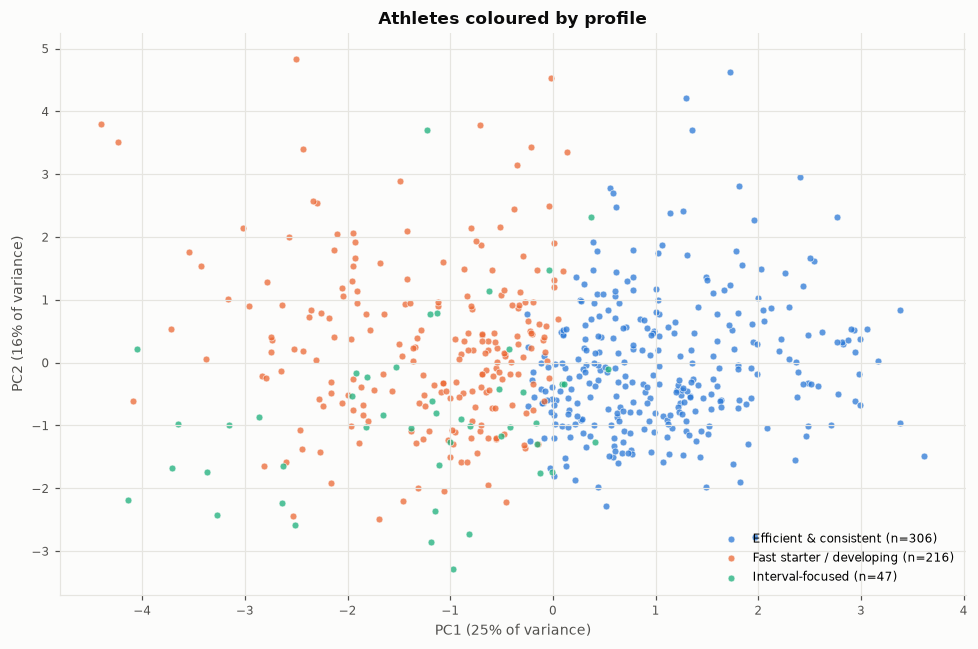

In [9]:
from sklearn.decomposition import PCA
pca = PCA(2).fit(X)
P = pca.transform(X)
fig, ax = plt.subplots(figsize=(9, 6))
for n in ORDER:
    m = (core.profile == n).to_numpy()
    ax.scatter(P[m, 0], P[m, 1], s=20, color=COLOR[n], alpha=0.75, lw=0.5, edgecolor="#fcfcfb",
               label=f"{n} (n={m.sum()})")
ev = pca.explained_variance_ratio_
ax.set(xlabel=f"PC1 ({ev[0]:.0%} of variance)", ylabel=f"PC2 ({ev[1]:.0%} of variance)",
       title="Athletes coloured by profile")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "profiles_pca.png", dpi=200, bbox_inches="tight")